In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Import Data

In [286]:
# import LMM20，26～29 GEMMA results

PATH_LMMs = './data' #enter the path of DEWAS results

LMM20 = pd.read_csv(PATH_LMMs+'LMM20_lmm.assoc.txt',sep='\t')
LMM26 = pd.read_csv(PATH_LMMs+'LMM26_lmm.assoc.txt',sep='\t')
LMM27 = pd.read_csv(PATH_LMMs+'LMM27_lmm.assoc.txt',sep='\t')
LMM28 = pd.read_csv(PATH_LMMs+'LMM28_lmm.assoc.txt',sep='\t')
LMM29 = pd.read_csv(PATH_LMMs+'LMM29_lmm.assoc.txt',sep='\t')

In [ ]:
# load illumina product file
df_ilmn_doc = pd.read_csv('xxx.csv')

In [ ]:
# load Lv3 data
df_imputed_train_set = pd.read_pkl('xxx.pkl')

## Methylation-Age Trajectory Chart

In [369]:
def cpg_trajectory_nodens_v2(df, cpg, gene_name, output_dir='./', cpg_col = "CpG", age_col = "Age",descret=False,save=False):
    # Plot - all together
    fig, axes = plt.subplots(1, 1, figsize = (4, 4))
    sns.kdeplot(data = df, x = age_col, y = cpg_col, levels=8, thresh=.1, color=colors['y3'])
    sns.regplot(ax = axes, data = df, x = age_col, y = cpg_col, marker = '.', scatter_kws={'alpha':0.5, 'rasterized':True,'color':colors['b3']}, line_kws={'color':"black"}, lowess = True)

    axes.set_ylabel("CpG Beta-Value")
    axes.set_ylim([0,1])
    axes.set_xlabel(age_col[1:])
    axes.set_title("%s | %s" % (cpg, gene_name))
    plt.tight_layout()
    for dp in [(.1,.9),(.15,.85),(.2,.8),(.25,.75)]:
        if dp == descret: 
            c='crimson'
            lst = '-'
        else: 
            c = 'grey'
            lst = '--'
        axes.axhline(dp[0],linestyle=lst,color=c,alpha=0.6)
        axes.axhline(dp[1],linestyle=lst,color=c,alpha=0.6)
    if save != False:
        plt.savefig(save + "%s_%s_trajectory_nodens.svg" % (cpg, gene_name), dpi = 300)
    plt.show()
    plt.close(fig)

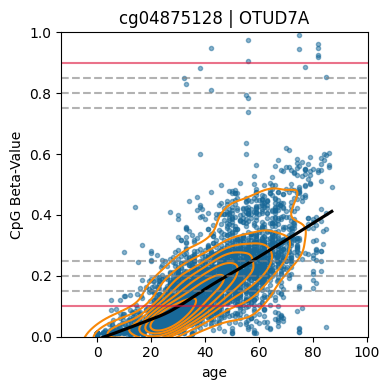

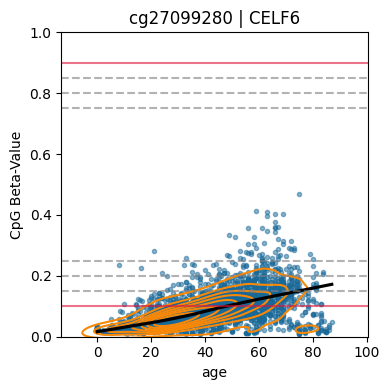

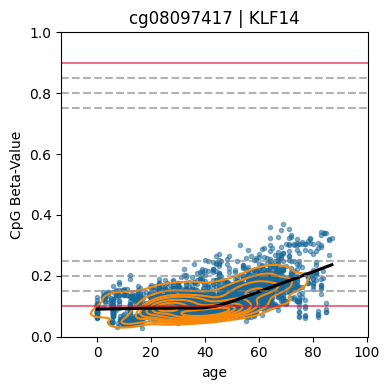

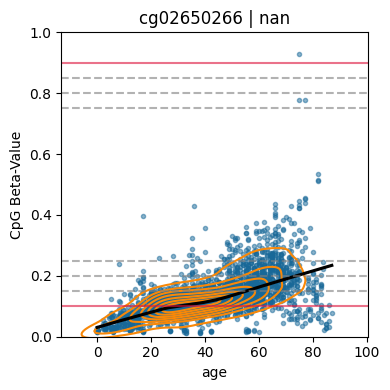

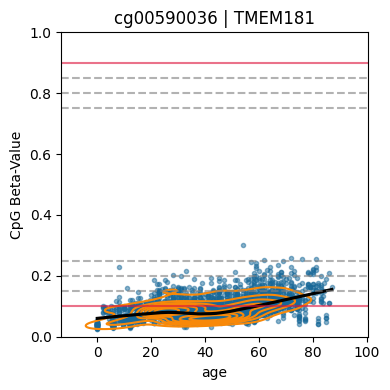

In [370]:
visaual_d1090 = df_agecpgs.sort_values(by='LMM26_rank').index[:5]

for cpg_site in visaual_d1090:
    cpg_trajectory_nodens_v2(df=df_imputed_train_set,cpg=cpg_site,
                          gene_name=re.sub('(;.*)','',str(df_ilmn_doc.loc[cpg_site]['UCSC_RefGene_Name'])),
                          cpg_col=cpg_site,age_col='!age',descret=(.1,.9))
                          #save='./fig/d1090_')

## QQ plot

In [413]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

def QQplot(LMM,save_name=None):
    # import pandas as pd
    # data = pd.read_csv('ewas_results.txt', sep='\t')
    p_values = LMM['p_wald'].values

    # calculate observed and expected -log10(p)
    obs_p = -np.log10(p_values + 1e-10)  # avoid log(0)
    obs_p = np.sort(obs_p)
    exp_p = -np.log10(np.arange(1, len(p_values) + 1) / (len(p_values) + 1))
    exp_p = np.sort(exp_p)

    # plot
    plt.figure(figsize=(4, 4))
    plt.scatter(exp_p, obs_p, s=10, c='blue', alpha=0.5, label='Observed vs\nExpected')
    plt.plot([0, max(exp_p)], [0, max(exp_p)], color='red', linestyle='--', label='y=x')

    # add the threshold of p-values
    threshold_p = 0.05/len(LMM.index)
    plt.axhline(y=-np.log10(1e-7), color='gray', linestyle='--', label='p=1e-7')

    plt.title(save_name, fontsize=14)
    plt.xlabel('Expected -log10(P)', fontsize=12)
    plt.ylabel('Observed -log10(P)', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    if save_name != None: plt.savefig('./fig/QQplot_'+save_name+'.png',dpi=300,bbox_inches='tight')
    plt.show()

    # calculate lambda
    chi2 = stats.chi2.ppf(1 - p_values, 1)
    lambda_gc = np.median(chi2) / stats.chi2.ppf(0.5, 1)
    print(f"Genomic Control Lambda: {lambda_gc:.3f}")

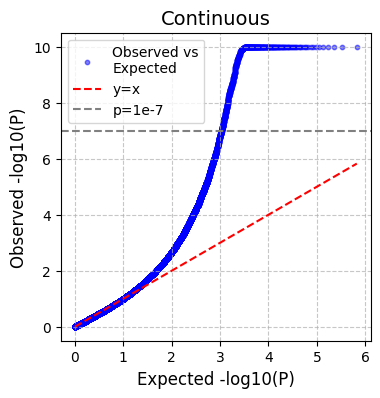

Genomic Control Lambda: 0.885


In [419]:
QQplot(LMM20,'Continuous')

## 曼哈顿图

In [433]:
def gemma2manhattan(LMM,doc_df):
    ageCpGs_lmm = pd.merge(LMM,doc_df[['CHR_hg38','Start_hg38']],left_on='rs',right_index=True)
    ageCpGs_lmm['CHR_hg38'] = ageCpGs_lmm['CHR_hg38'].str.replace('chr','').str.zfill(2)
    ageCpGs_lmm['CHR_hg38'] = ageCpGs_lmm['CHR_hg38'].str.replace('0X','X')
    ageCpGs_lmm['CHR_hg38'] = ageCpGs_lmm['CHR_hg38'].str.replace('0Y','Y')
    ageCpGs_lmm.sort_values(['CHR_hg38','Start_hg38'],inplace=True)
    ageCpGs_lmm.reset_index(inplace=True,drop=True)
    return ageCpGs_lmm

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Input data format: Each row represents a cg, and must contain two columns named "CHR-hg38" and "p_wald", representing the chromosome and p-value of the cg, respectively. 
# All cgs are sorted in ascending order according to mapinfo. index represents the ranking after sorting.
# The input cut_input indicates whether to truncate the y-axis, supporting multiple truncations, and must be provided as a list. 
# For example, to truncate the y-axis into two segments at -logp=40, input [40].
def manhattan_plot(gwas_sumstats,cut_input=[],palette='dark',save=False,annot=True):
    gwas_sumstats["i"]=gwas_sumstats.index
    gwas_sumstats["nega_lg_p"] = -np.log10(gwas_sumstats["p_wald"])
    nega_lg_p_max = gwas_sumstats["nega_lg_p"].max()
    threshold_p = 0.05/len(gwas_sumstats.index)
    if annot: annote_list = gwas_sumstats.sort_values('p_wald').iloc[:5][['i','nega_lg_p','rs']] #要标注信息的top10位点。
    else: annote_list=pd.DataFrame([])
    
    d = .5  # proportion of vertical to horizontal extent of the slanted line
    kwargs = dict(marker=[(-1, -d), (1, d)], markersize=12,linestyle="none", color='k', mec='k', mew=1, clip_on=False)

    if len(cut_input) == 0:
        fig,axs = plt.subplots(1,1,figsize=(4*SUI,SUI))
        sns.scatterplot(data=gwas_sumstats, x='i', y='nega_lg_p',hue='CHR_hg38',palette=palette, s=4,legend=None,linewidth=0)
        chrom_df=gwas_sumstats.groupby('CHR_hg38')['i'].median()
        axs.set_xticks(chrom_df)
        axs.set_xticklabels(chrom_df.index)
        for label in axs.get_xticklabels(which='major'):
            label.set(rotation=90, horizontalalignment='center')
        axs.set_xlabel('CHR_hg38')
        axs.set_ylabel('-log(P)')    
        axs.axhline(y=-np.log10(threshold_p), linewidth = 2,linestyle="--",color="grey")
        
        for i in range(annote_list.shape[0]):
            plt.text(annote_list.iloc[i]['i'],annote_list.iloc[i]['nega_lg_p'],annote_list.iloc[i]['rs'],fontsize=6,horizontalalignment='center',color='grey')
        
    if len(cut_input) > 0:
        cut_input.sort(reverse=True)
        cut = [nega_lg_p_max*1.1]+cut_input+[0]
        print(cut)
        cut_axs = []
        fig,axs = plt.subplots(len(cut)-1,1,figsize=(4*SUI,SUI),sharex=True)
        for i in range(len(cut)-1):
            sns.scatterplot(data=gwas_sumstats, x='i', y='nega_lg_p',hue='CHR_hg38',palette=palette, s=4,ax=axs[i],legend=None,linewidth=0)
            print(cut[i+1],cut[i])
            cut_axs.append(((cut[i+1],cut[i]),axs[i]))
            axs[i].set_ylim(cut[i+1],cut[i])
            axs[i].spines.bottom.set_visible(False)
            axs[i].spines.top.set_visible(False)
            axs[i].set_ylabel('')
            if i != 0: axs[i].plot([0, 1], [1, 1], transform=axs[i].transAxes, **kwargs)
            if i != (len(cut)-2): axs[i].plot([0, 1], [0, 0], transform=axs[i].transAxes, **kwargs)
        axs[0].spines.top.set_visible(True)
        axs[0].tick_params(labeltop=False,bottom=False)
        axs[-1].xaxis.tick_bottom()
        axs[-1].spines.bottom.set_visible(True)
        chrom_df=gwas_sumstats.groupby('CHR_hg38')['i'].median()
        axs[-1].set_xticks(chrom_df)
        axs[-1].set_xticklabels(chrom_df.index)
        for label in axs[-1].get_xticklabels(which='major'):
            label.set(rotation=90, horizontalalignment='center')
        axs[-1].set_xlabel('CHR_hg38') 
        axs[-1].axhline(y=-np.log10(threshold_p), linewidth = 2,linestyle="--",color="grey")
        ylabel_loc_x = -0.12*gwas_sumstats.shape[0]
        if cut_input != None:
            ylabel_loc_y = min(cut_input)*(len(cut_input)+1)/2
        else: ylabel_locy = nega_lg_p_max/2
        plt.text(ylabel_loc_x-15000,ylabel_loc_y,'-log(P)',rotation=90) # ylabel 设置
        for i in range(annote_list.shape[0]):
            for j in cut_axs:
                if annote_list.iloc[i]['nega_lg_p'] >= j[0][0] and annote_list.iloc[i]['nega_lg_p'] < j[0][1]:
                    j[1].text(annote_list.iloc[i]['i'],annote_list.iloc[i]['nega_lg_p'],annote_list.iloc[i]['rs'],fontsize=6,horizontalalignment='center',color='grey')
        
    
    #fig.suptitle(title)
    if save!=False: plt.savefig(save+'.tif',dpi=300,bbox_inches='tight')

In [289]:
ageCpGs_lmm20 = gemma2manhattan(LMM20,df_ilmn_doc)
ageCpGs_lmm26 = gemma2manhattan(LMM26,df_ilmn_doc)
ageCpGs_lmm27 = gemma2manhattan(LMM27,df_ilmn_doc)
ageCpGs_lmm28 = gemma2manhattan(LMM28,df_ilmn_doc)
ageCpGs_lmm29 = gemma2manhattan(LMM29,df_ilmn_doc)

[152.77635498044117, 38, 0]


/tmp/ipykernel_1227512/2841175643.py:50: UserWarning: 
The palette list has fewer values (2) than needed (24) and will cycle, which may produce an uninterpretable plot.
  sns.scatterplot(data=gwas_sumstats, x='i', y='nega_lg_p',hue='CHR_hg38',palette=palette, s=4,ax=axs[i],legend=None,linewidth=0)


38 152.77635498044117


/tmp/ipykernel_1227512/2841175643.py:50: UserWarning: 
The palette list has fewer values (2) than needed (24) and will cycle, which may produce an uninterpretable plot.
  sns.scatterplot(data=gwas_sumstats, x='i', y='nega_lg_p',hue='CHR_hg38',palette=palette, s=4,ax=axs[i],legend=None,linewidth=0)


0 38


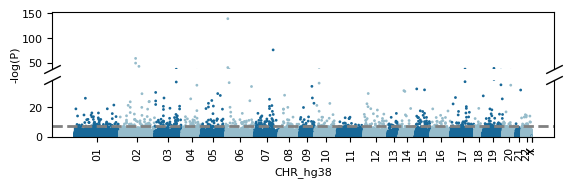

In [439]:
manhattan_plot(ageCpGs_lmm20,[38],
               #palette=sns.cubehelix_palette(2, start=2.8, rot=0, dark=.3, light=.6, reverse=True),
               palette=[RYB01['b3'],RYB01['b2']], 
               save='./fig/0519/manht-lmm20',
               annot=False)